In [ ]:
import os
import os.path as op

import matplotlib.pyplot as plt

import hnn_core

from hnn_core import MPIBackend

from optim_utils import set_params
from hnn_core.dipole import _rmse
from hnn_core.params import _short_name

from hnn_core import human_ET_model, simulate_dipole, jones_2009_model

pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/figures/'


In [6]:
import pickle
with open('handtuned_post_opt.pkl', 'rb') as file:
    hand_tune_opt = pickle.load(file)

In [7]:
def simu_mu_erp(net, external_drives, weights_ampa_p, weights_ampa_d, stim_onset, bsl_cor='calcium'):

    tstop = 1000

    location = 'proximal'
    burst_std = 20    
    syn_delays_p = {'L2_basket': 4., 'L2_pyramidal': 5, 'L5_pyramidal': 5., 'L5_basket': 4}#{'L2_basket': 0.1, 'L5_pyramidal': 1., 'L5_basket': 1}                    # following https://modeldb.science/136803?tab=2&file=JonesEtAl2009/wiring_proc_2Dv2.hoc {'L2_basket': 4., 'L5_pyramidal': 5., 'L5_basket': 4} but this leads to no response at all

    net.add_bursty_drive(
    'alpha_prox', tstart=50., burst_rate=10, burst_std=burst_std, numspikes=2,
    spike_isi=10, n_drive_cells=10, location=location,
    weights_ampa=weights_ampa_p, synaptic_delays=syn_delays_p, event_seed=284)

    location = 'distal'
    burst_std = 20              # I believe the std was the same for FB and FF inputs in Jones 2009

    syn_delays_d = {'L2_basket': 4, 'L5_pyramidal': 5., 'L2_pyramidal': 5.}



    delay = 3                  
    net.add_bursty_drive(
        'alpha_dist', tstart=50.+delay, burst_rate=10, burst_std=burst_std, numspikes=2,
        spike_isi=10, n_drive_cells=10, location=location,
        weights_ampa=weights_ampa_d, synaptic_delays=syn_delays_d, event_seed=296)


    # sequence Jones page 11
    # FF 25 ms
    # FB 70 ms
    # FF 135

    synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                        'L5_basket': 1., 'L5_pyramidal': 1.}

    erp_on = external_drives['prox1']['dynamics']['mu']
    
    net.add_evoked_drive('prox1',
                            mu=stim_onset,            # yes this is redundant but need to do this for  my own logic
                            sigma=external_drives['prox1']['dynamics']['sigma'],
                            numspikes=external_drives['prox1']['dynamics']['numspikes'],
                            location='proximal',
                            weights_ampa=external_drives['prox1']['weights_ampa'],
                            weights_nmda=external_drives['prox1']['weights_nmda'],
                            synaptic_delays=synaptic_delays_p, event_seed=544)
    synaptic_delays_d = {'L2_basket': 0.1, 'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}
    net.add_evoked_drive('dist',    
                        mu = stim_onset-erp_on+external_drives['dist']['dynamics']['mu'],
                        sigma=external_drives['dist']['dynamics']['sigma'],
                        numspikes=external_drives['dist']['dynamics']['numspikes'],
                        location='distal',
                        weights_ampa=external_drives['dist']['weights_ampa'],
                        weights_nmda=external_drives['dist']['weights_nmda'],
                        synaptic_delays=synaptic_delays_d, event_seed=544)

    net.add_evoked_drive('prox2',
                            mu=stim_onset-erp_on+external_drives['prox2']['dynamics']['mu'],
                            sigma=external_drives['prox2']['dynamics']['sigma'],
                            numspikes=external_drives['prox2']['dynamics']['numspikes'],
                            location='proximal',
                            weights_ampa=external_drives['prox2']['weights_ampa'],
                            weights_nmda=external_drives['prox2']['weights_nmda'],
                            synaptic_delays=synaptic_delays_p, event_seed=544)
    
    with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
        dpl = simulate_dipole(net, tstop=tstop, n_trials=1, bsl_cor=bsl_cor)[0]


    return dpl, net

### New model

In [ ]:
# find mu phase

# High mu
scale_factor = 300
stim_onset = 530

net_high = human_ET_model()
tstop = 1000

location = 'proximal'
burst_std = 20               # Jones 2009: input bursts variance = 400


weights_ampa_p = {'L2_basket': 1.2e-7, 'L2_pyramidal': 0.6e-7, 'L5_pyramidal': 0.6e-7, 'L5_basket': 1.2e-7}     # max values taken from Jones 2009 for high mu; 

syn_delays_p = {'L2_basket': 4., 'L2_pyramidal': 5, 'L5_pyramidal': 5., 'L5_basket': 4}#{'L2_basket': 0.1, 'L5_pyramidal': 1., 'L5_basket': 1}                    # following https://modeldb.science/136803?tab=2&file=JonesEtAl2009/wiring_proc_2Dv2.hoc {'L2_basket': 4., 'L5_pyramidal': 5., 'L5_basket': 4} but this leads to no response at all

net_high.add_bursty_drive(
    'alpha_prox', tstart=50., burst_rate=10, burst_std=burst_std, numspikes=2,
    spike_isi=10, n_drive_cells=10, location=location,
    weights_ampa=weights_ampa_p, synaptic_delays=syn_delays_p, event_seed=284)

location = 'distal'
burst_std = 20              # I believe the std was the same for FB and FF inputs in Jones 2009
weights_ampa_d = {'L2_basket': 1.2e-7*4*10, 'L5_pyramidal': 0.6e-7*4*10, 'L2_pyramidal': 0.6e-7*4*10}  # max values taken from Jones 2009 for high mu; FB connections 4x stronger accotding to https://modeldb.science/136803?tab=2&file=JonesEtAl2009/E-FFFBx_fixed_10.hoc
syn_delays_d = {'L2_basket': 4, 'L5_pyramidal': 5., 'L2_pyramidal': 5.}



delay = 3                  
net_high.add_bursty_drive(
    'alpha_dist', tstart=50.+delay, burst_rate=10, burst_std=burst_std, numspikes=2,
    spike_isi=10, n_drive_cells=10, location=location,
    weights_ampa=weights_ampa_d, synaptic_delays=syn_delays_d, event_seed=296)

with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
    dpl_high = simulate_dipole(net_high, tstop=tstop, n_trials=1, bsl_cor='calcium')[0]

dpl_high.smooth(15)

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/k

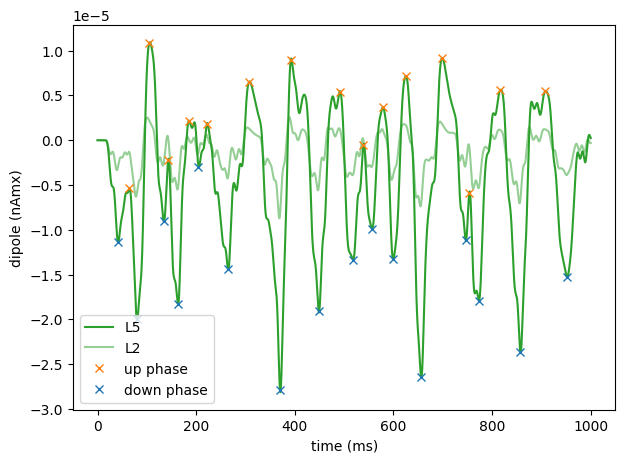

In [9]:
# find phase

from scipy.signal import find_peaks
up_phase, _ = find_peaks(dpl_high.data['agg'], prominence=5e-6)

down_phase, _ = find_peaks(-dpl_high.data['agg'], prominence=5e-6)

fig, ax = plt.subplots(1, 1, figsize=(7, 5))
ax.plot(dpl_high.times, dpl_high.data['L5'], color='tab:green', label='L5')
ax.plot(dpl_high.times, dpl_high.data['L2'], color='tab:green', alpha=0.5, label='L2')

ax.plot(dpl_high.times[up_phase], dpl_high.data['L5'][up_phase], color='tab:orange', marker='x', linestyle='None', label='up phase')
ax.plot(dpl_high.times[down_phase], dpl_high.data['L5'][down_phase], color='tab:blue', marker='x', linestyle='None', label='down phase')
ax.set_xlabel('time (ms)')
ax.set_ylabel(f'dipole (nAmx)')
ax.legend()
fig.savefig(os.path.join(pathfig, 'mu_phase.png'))
fig.savefig(os.path.join(pathfig, 'mu_phase.pdf'))

In [ ]:
# High mu
net = human_ET_model()

up_onset = dpl_high.times[up_phase][-4]

weights_ampa_p = {'L2_basket': 1.2e-7*100, 'L2_pyramidal': 0.6e-7*100, 'L5_pyramidal': 0.6e-7*100, 'L5_basket': 1.2e-7*100}     # max values taken from Jones 2009 for high mu; 

weights_ampa_d = {'L2_basket': 1.2e-7*4*100, 'L5_pyramidal': 0.6e-7*4*100, 'L2_pyramidal': 0.6e-7*4*100}  # max values taken from Jones 2009 for high mu; FB connections 4x stronger accotding to https://modeldb.science/136803?tab=2&file=JonesEtAl2009/E-FFFBx_fixed_10.hoc

dpl_high_up, net_high_up = simu_mu_erp(net, hand_tune_opt.external_drives,weights_ampa_p, weights_ampa_d, up_onset)

net = human_ET_model()
# low mu
weights_ampa_p = {'L2_basket': 0.8e-7*10, 'L2_pyramidal': 0.4e-7*10, 'L5_pyramidal': 0.4e-7*10, 'L5_basket': 0.8e-7*10}     # max values taken from Jones 2009 for high mu; 
weights_ampa_d = {'L2_basket': 0.8e-7*4*10, 'L5_pyramidal': 0.4e-7*4*10, 'L2_pyramidal': 0.4e-7*4*10}   # max values taken from Jones 2009 for high mu; FB connections 4x stronger accotding to https://modeldb.science/136803?tab=2&file=JonesEtAl2009/E-FFFBx_fixed_10.hoc

dpl_low_up, net_low_up = simu_mu_erp(net, hand_tune_opt.external_drives,weights_ampa_p, weights_ampa_d, up_onset)


# down phase
net = human_ET_model()
# high
down_onset = dpl_high.times[down_phase][-5]

weights_ampa_p = {'L2_basket': 1.2e-7*100, 'L2_pyramidal': 0.6e-7*100, 'L5_pyramidal': 0.6e-7*100, 'L5_basket': 1.2e-7*100}     # max values taken from Jones 2009 for high mu; 

weights_ampa_d = {'L2_basket': 1.2e-7*4*100, 'L5_pyramidal': 0.6e-7*4*100, 'L2_pyramidal': 0.6e-7*4*100}  # max values taken from Jones 2009 for high mu; FB connections 4x stronger accotding to https://modeldb.science/136803?tab=2&file=JonesEtAl2009/E-FFFBx_fixed_10.hoc

dpl_high_down, net_high_down = simu_mu_erp(net, hand_tune_opt.external_drives,weights_ampa_p, weights_ampa_d, down_onset)

net = human_ET_model()
# low mu
weights_ampa_p = {'L2_basket': 0.8e-7*10, 'L2_pyramidal': 0.4e-7*10, 'L5_pyramidal': 0.4e-7*10, 'L5_basket': 0.8e-7*10}     # max values taken from Jones 2009 for high mu; 
weights_ampa_d = {'L2_basket': 0.8e-7*4*10, 'L5_pyramidal': 0.4e-7*4*10, 'L2_pyramidal': 0.4e-7*4*10}  # max values taken from Jones 2009 for high mu; FB connections 4x stronger accotding to https://modeldb.science/136803?tab=2&file=JonesEtAl2009/E-FFFBx_fixed_10.hoc

dpl_low_down, net_low_down = simu_mu_erp(net, hand_tune_opt.external_drives, weights_ampa_p, weights_ampa_d, down_onset)

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/k

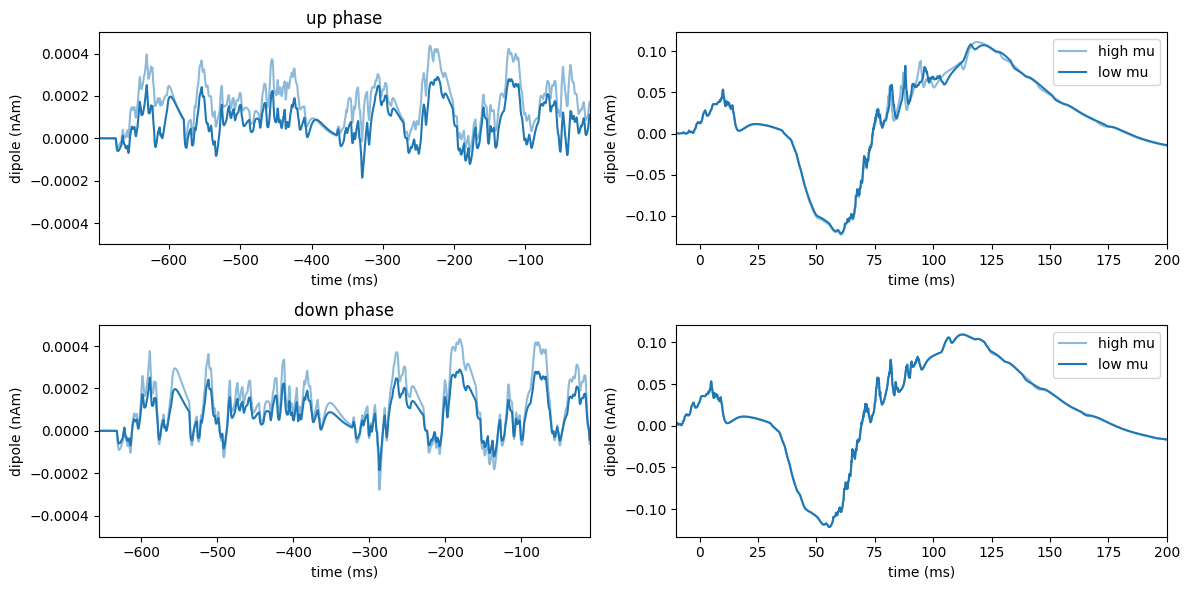

In [24]:
fig, ax = plt.subplots(2, 2, figsize=(12, 6))

timevec = dpl_high_up.times-up_onset
ax = ax.flatten()
ax[0].plot(timevec, dpl_high_up.data['agg'], label='high mu', color='tab:blue', alpha=0.5)
ax[0].plot(timevec, dpl_low_up.data['agg'], label='low mu', color='tab:blue')
ax[0].set_xlabel('time (ms)')
ax[0].set_ylabel(f'dipole (nAm)')
ax[0].set_xlim((timevec[0], -10))
ax[0].set_ylim((-5e-4, 5e-4))

ax[1].plot(dpl_high_up.times-up_onset, dpl_high_up.data['agg'], label='high mu', color='tab:blue', alpha=0.5)
ax[1].plot(dpl_low_up.times-up_onset, dpl_low_up.data['agg'], label='low mu', color='tab:blue')
ax[1].set_xlabel('time (ms)')
ax[1].set_ylabel(f'dipole (nAm)')
ax[1].set_xlim((-10, 200))
ax[1].legend()


timevec = dpl_high_up.times-down_onset

ax[2].plot(dpl_high_down.times-down_onset, dpl_high_down.data['agg'], label='high mu', color='tab:blue', alpha=0.5)
ax[2].plot(dpl_low_down.times-down_onset, dpl_low_down.data['agg'], label='low mu', color='tab:blue')
ax[2].set_xlabel('time (ms)')
ax[2].set_ylabel(f'dipole (nAm)')
ax[2].set_xlim((timevec[0], -10))
ax[2].set_ylim((-5e-4, 5e-4))
ax[3].plot(dpl_high_down.times-down_onset-5, dpl_high_down.data['agg'], label='high mu', color='tab:blue', alpha=0.5)
ax[3].plot(dpl_low_down.times-down_onset-5, dpl_low_down.data['agg'], label='low mu', color='tab:blue')
ax[3].set_xlabel('time (ms)')
ax[3].set_ylabel(f'dipole (nAm)')
ax[3].set_xlim((-10, 200))
ax[3].legend()
ax[0].set_title('up phase')
ax[2].set_title('down phase')

fig.tight_layout()
fig.savefig(os.path.join(pathfig, 'ERP_yes_new_drives_high_low_mu_phase.png'))
fig.savefig(os.path.join(pathfig, 'ERP_yes_new_drives_high_low_mu_phase.pdf'))

## Can I reproduce Jones model?

In [12]:
jones2009_erp = dict()
jones2009_erp['prox1'] = dict()
jones2009_erp['prox1']['dynamics'] = dict()
jones2009_erp['prox1']['dynamics']['mu'] = 25
jones2009_erp['prox1']['dynamics']['sigma'] = hand_tune_opt.external_drives['prox1']['dynamics']['sigma']
jones2009_erp['prox1']['dynamics']['numspikes'] = 1
jones2009_erp['prox1']['weights_ampa'] = {'L2_basket': 0.002,
                                        'L2_pyramidal': 0.001,
                                        'L5_basket': 0.001,
                                        'L5_pyramidal': 0.0005}
jones2009_erp['prox1']['weights_nmda'] = {'L2_basket': 0.002,
                                        'L2_pyramidal': 0.001,
                                        'L5_basket': 0.001,
                                        'L5_pyramidal': 0.0005}

jones2009_erp['dist'] = dict()
jones2009_erp['dist']['dynamics'] = dict()
jones2009_erp['dist']['dynamics']['mu'] = 70
jones2009_erp['dist']['dynamics']['sigma'] = hand_tune_opt.external_drives['dist']['dynamics']['sigma']
jones2009_erp['dist']['dynamics']['numspikes'] = 1
jones2009_erp['dist']['weights_ampa'] = {'L2_basket': 0.0005,
                                     'L2_pyramidal': 0.001,
                                     'L5_pyramidal': 0.001}
jones2009_erp['dist']['weights_nmda'] = {'L2_basket': 0.0005,
                                     'L2_pyramidal': 0.001,
                                     'L5_pyramidal': 0.001}

jones2009_erp['prox2'] = dict()
jones2009_erp['prox2']['dynamics'] = dict()
jones2009_erp['prox2']['dynamics']['mu'] = 135
jones2009_erp['prox2']['dynamics']['sigma'] = hand_tune_opt.external_drives['prox2']['dynamics']['sigma']
jones2009_erp['prox2']['dynamics']['numspikes'] = 2
jones2009_erp['prox2']['weights_ampa'] = {'L2_basket': 0.0053,
                                        'L2_pyramidal': 0.0053,
                                        'L5_basket': 0.0027,
                                        'L5_pyramidal': 0.0027}
jones2009_erp['prox2']['weights_nmda'] = {'L2_basket': 0.0053,
                                        'L2_pyramidal': 0.0053,
                                        'L5_basket': 0.0027,
                                        'L5_pyramidal': 0.0027}

In [13]:

# high mu
net = jones_2009_model()

stim_onset = 575
timevec = dpl_high_up.times-stim_onset

weights_ampa_p = {'L2_basket': 1.2e-7, 'L2_pyramidal': 0.6e-7, 'L5_pyramidal': 0.6e-7, 'L5_basket': 1.2e-7}     # max values taken from Jones 2009 for high mu; 

weights_ampa_d = {'L2_basket': 1.2e-7*4, 'L5_pyramidal': 0.6e-7*4, 'L2_pyramidal': 0.6e-7*4}  # max values taken from Jones 2009 for high mu; FB connections 4x stronger accotding to https://modeldb.science/136803?tab=2&file=JonesEtAl2009/E-FFFBx_fixed_10.hoc

dpl_high, net_high = simu_mu_erp(net, jones2009_erp, weights_ampa_p, weights_ampa_d, stim_onset, bsl_cor='jones')

# low mu
net = jones_2009_model()

weights_ampa_p = {'L2_basket': 0.8e-7, 'L2_pyramidal': 0.4e-7, 'L5_pyramidal': 0.4e-7, 'L5_basket': 0.8e-7}     # max values taken from Jones 2009 for high mu;
weights_ampa_d = {'L2_basket': 0.8e-7*4, 'L5_pyramidal': 0.4e-7*4, 'L2_pyramidal': 0.4e-7*4}  # max values taken from Jones 2009 for high mu; FB connections 4x stronger accotding to https://modeldb.science/136803?tab=2&file=JonesEtAl2009/E-FFFBx_fixed_10.hoc
dpl_low, net_low = simu_mu_erp(net, jones2009_erp, weights_ampa_p, weights_ampa_d, stim_onset, bsl_cor='jones')



MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/k

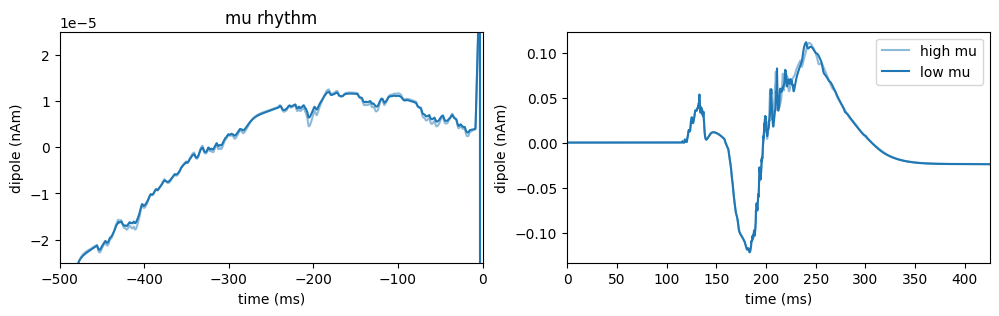

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
timevec = dpl_high.times-stim_onset
ax[0].plot(timevec, dpl_high.data['agg'], label='high mu', color='tab:blue', alpha=0.5)
ax[0].plot(timevec, dpl_low.data['agg'], label='low mu', color='tab:blue')
ax[0].set_xlabel('time (ms)')
ax[0].set_ylabel(f'dipole (nAm)')
ax[0].set_xlim((-500, 0))
ax[0].set_ylim((-2.5e-5, 2.5e-5))   
ax[1].set_xlim((0, timevec[-1]))    
ax[0].set_title('mu rhythm')
ax[1].plot(timevec, dpl_high_up.data['agg'], label='high mu', color='tab:blue', alpha=0.5)
ax[1].plot(timevec, dpl_low_up.data['agg'], label='low mu', color='tab:blue')
ax[1].set_xlabel('time (ms)')
ax[1].set_ylabel(f'dipole (nAm)')
ax[1].legend()

fig.savefig(os.path.join(pathfig, 'reproduce_Jones2009_ERP_mu.png'))
fig.savefig(os.path.join(pathfig, 'reproduce_Jones2009_ERP_mu.pdf'))

In [15]:
net = jones_2009_model()

weights_ampa_p = {'L2_basket': 1.2e-7, 'L2_pyramidal': 0.6e-7, 'L5_pyramidal': 0.6e-7, 'L5_basket': 1.2e-7}     # max values taken from Jones 2009 for high mu; 

weights_ampa_d = {'L2_basket': 1.2e-7*4, 'L5_pyramidal': 0.6e-7*4, 'L2_pyramidal': 0.6e-7*4}  # max values taken from Jones 2009 for high mu; FB connections 4x stronger accotding to https://modeldb.science/136803?tab=2&file=JonesEtAl2009/E-FFFBx_fixed_10.hoc

tstop = 1000

location = 'proximal'
burst_std = 20    
syn_delays_p = {'L2_basket': 4., 'L2_pyramidal': 5, 'L5_pyramidal': 5., 'L5_basket': 4}#{'L2_basket': 0.1, 'L5_pyramidal': 1., 'L5_basket': 1}                    # following https://modeldb.science/136803?tab=2&file=JonesEtAl2009/wiring_proc_2Dv2.hoc {'L2_basket': 4., 'L5_pyramidal': 5., 'L5_basket': 4} but this leads to no response at all

net.add_bursty_drive(
'alpha_prox', tstart=50., burst_rate=10, burst_std=burst_std, numspikes=2,
spike_isi=10, n_drive_cells=10, location=location,
weights_ampa=weights_ampa_p, synaptic_delays=syn_delays_p, event_seed=284)

location = 'distal'
burst_std = 20              # I believe the std was the same for FB and FF inputs in Jones 2009

syn_delays_d = {'L2_basket': 4, 'L5_pyramidal': 5., 'L2_pyramidal': 5.}



delay = 3                  
net.add_bursty_drive(
    'alpha_dist', tstart=50.+delay, burst_rate=10, burst_std=burst_std, numspikes=2,
    spike_isi=10, n_drive_cells=10, location=location,
    weights_ampa=weights_ampa_d, synaptic_delays=syn_delays_d, event_seed=296)

with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
    dpl = simulate_dipole(net, tstop=1000, n_trials=1)[0]

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/k

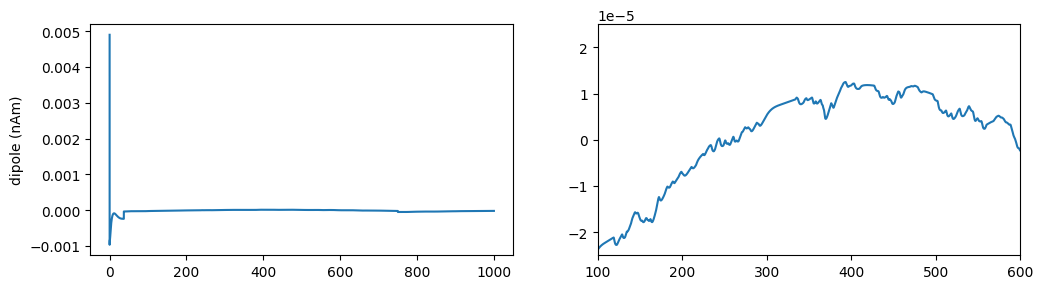

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3))

ax[0].plot(dpl.times, dpl.data['agg'])
ax[1].plot(dpl.times, dpl.data['agg'])
ax[0].set_ylabel(f'dipole (nAm)')
ax[1].set_xlim((100,600))
ax[1].set_ylim((-2.5e-5, 2.5e-5))

fig.savefig(os.path.join(pathfig, 'mu_rhythm_jones2009.png'))
fig.savefig(os.path.join(pathfig, 'mu_rhythm_jones2009.pdf'))